In [3]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import os

DATA_DIR = "/content/drive/MyDrive/IDA-THL-Dataset-Phase-I"

print("Exists:", os.path.exists(DATA_DIR))
print("Contents:", os.listdir(DATA_DIR) if os.path.exists(DATA_DIR) else "NOT FOUND")

Exists: True
Contents: ['0', '1']


In [5]:
DATA_DIR = "/content/drive/MyDrive/IDA-THL-Dataset-Phase-I"

In [6]:
from glob import glob

ida_images = glob(DATA_DIR + "/0/**/*.png", recursive=True)
thl_images = glob(DATA_DIR + "/1/**/*.png", recursive=True)

print("IDA images:", len(ida_images))
print("THL images:", len(thl_images))

if ida_images:
    print("Sample image:", ida_images[0])

IDA images: 1541
THL images: 3931
Sample image: /content/drive/MyDrive/IDA-THL-Dataset-Phase-I/0/IDA-004/cells/DSC10001/30717-51-DSC10001-01.png


In [7]:
from glob import glob

all_files_0 = glob(DATA_DIR + "/0/**/*", recursive=True)
all_files_1 = glob(DATA_DIR + "/1/**/*", recursive=True)

print("Total files in 0 folder:", len(all_files_0))
print("Total files in 1 folder:", len(all_files_1))

Total files in 0 folder: 1651
Total files in 1 folder: 4056


In [8]:
import random

In [9]:
# import random
# random.seed(42)

ida_images = random.sample(ida_images, 500)
thl_images = random.sample(thl_images, 500)

print("Using IDA images:", len(ida_images))
print("Using THL images:", len(thl_images))



Using IDA images: 500
Using THL images: 500


In [10]:
from sklearn.model_selection import train_test_split

In [11]:

# Combine IDA and THL image paths with labels
image_paths = ida_images + thl_images
labels = [0]*len(ida_images) + [1]*len(thl_images)

# Shuffle images and labels together to avoid ordering bias
combined = list(zip(image_paths, labels))
random.shuffle(combined)
image_paths, labels = zip(*combined)

# Split into training and validation sets (80% / 20%)
train_p, val_p, train_y, val_y = train_test_split(
    list(image_paths),
    list(labels),
    test_size=0.2,
    stratify=labels,
    random_state=42
)

print("Training samples:", len(train_p))
print("Validation samples:", len(val_p))


Training samples: 800
Validation samples: 200


In [12]:
from torch.utils.data import Dataset

In [13]:

class BloodCellDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, self.labels[idx]



In [14]:
from torchvision import transforms

In [15]:
from torch.utils.data import Dataset, DataLoader

In [16]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

train_ds = BloodCellDataset(train_p, train_y, transform)
val_ds = BloodCellDataset(val_p, val_y, transform)

train_loader = DataLoader(train_ds, batch_size=8, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=8, shuffle=False)


In [17]:
import torch
import torch.nn as nn
from torchvision import models

In [18]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = models.efficientnet_b0(weights="IMAGENET1K_V1")
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 2)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)


Using device: cpu
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 172MB/s]


In [19]:
from PIL import Image

In [20]:
epochs = 3

for epoch in range(epochs):
    model.train()
    running_loss = 0

    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, lbls)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss/len(train_loader):.4f}")


Epoch 1/3, Loss: 0.5835
Epoch 2/3, Loss: 0.3464
Epoch 3/3, Loss: 0.2180


In [21]:
# Modified training loop to store loss and accuracy history for plotting

# Initialize lists to store metrics if they don't exist
if 'training_losses' not in globals():
    training_losses = []
if 'training_accuracies' not in globals():
    training_accuracies = []
if 'validation_losses' not in globals():
    validation_losses = []
if 'validation_accuracies' not in globals():
    validation_accuracies = []

epochs = 3 # This should match the original epochs from the cell

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct_train, total_train = 0, 0

    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, lbls)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * imgs.size(0) # Multiply by batch size for correct average
        _, predicted_train = torch.max(outputs.data, 1)
        total_train += lbls.size(0)
        correct_train += (predicted_train == lbls).sum().item()

    epoch_train_loss = running_loss / len(train_loader.dataset)
    epoch_train_acc = correct_train / total_train
    training_losses.append(epoch_train_loss)
    training_accuracies.append(epoch_train_acc)

    # Validation phase
    model.eval()
    running_val_loss = 0.0
    correct_val, total_val = 0, 0
    with torch.no_grad():
        for imgs, lbls in val_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, lbls)
            running_val_loss += loss.item() * imgs.size(0)
            _, predicted_val = torch.max(outputs.data, 1)
            total_val += lbls.size(0)
            correct_val += (predicted_val == lbls).sum().item()

    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    epoch_val_acc = correct_val / total_val
    validation_losses.append(epoch_val_loss)
    validation_accuracies.append(epoch_val_acc)

    print(f"Epoch {epoch+1}/{epochs}, "
          f"Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.4f}, "
          f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.4f}")


Epoch 1/3, Train Loss: 0.1597, Train Acc: 0.9387, Val Loss: 0.3282, Val Acc: 0.8850
Epoch 2/3, Train Loss: 0.1114, Train Acc: 0.9650, Val Loss: 0.2849, Val Acc: 0.8800
Epoch 3/3, Train Loss: 0.1318, Train Acc: 0.9525, Val Loss: 0.3157, Val Acc: 0.8900


In [22]:
model.eval()
correct, total = 0, 0

with torch.no_grad():
    for imgs, lbls in val_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)
        outputs = model(imgs)
        preds = torch.argmax(outputs, 1)

        correct += (preds == lbls).sum().item()
        total += lbls.size(0)

accuracy = correct / total
print("Validation Accuracy:", round(accuracy*100, 2), "%")


Validation Accuracy: 89.0 %


In [23]:
import tensorflow as tf
import numpy as np
import cv2
from tensorflow.keras.models import Model

def generate_gradcam(model, image, layer_name):
    grad_model = Model(
        inputs=model.input,  # original model input
        outputs=[model.get_layer(layer_name).output, model.output]  # conv layer + final output
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(image)
        loss = predictions[:, 0]

    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap = tf.reduce_mean(tf.multiply(pooled_grads, conv_outputs), axis=-1)
    heatmap = np.maximum(heatmap[0], 0)
    heatmap /= np.max(heatmap)

    return heatmap

print("Explainable AI Module Executed")

Explainable AI Module Executed


In [24]:
import torch
import torch.nn.functional as F
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image
import random

def generate_pytorch_gradcam(model, original_image, transform, target_layer_module, device):
    """
    Generates a Grad-CAM heatmap for a given PyTorch model and image.

    Args:
        model (torch.nn.Module): The trained PyTorch model.
        original_image (PIL.Image.Image): The input image.
        transform (torchvision.transforms): The transformation applied to the image
                                             before passing to the model.
        target_layer_module (torch.nn.Module): The module (layer) to extract activations and gradients from.
        device (torch.device): The device (cuda or cpu) the model and tensors are on.

    Returns:
        tuple: (gradcam_heatmap, predicted_class_idx, predicted_score)
    """
    model.eval()

    # Store activations and gradients
    activations = None
    gradients = None

    def save_activation(module, input, output):
        nonlocal activations
        activations = output

    def save_gradient(module, grad_input, grad_output):
        nonlocal gradients
        gradients = grad_output[0]

    # Register hooks
    hook_handles = []
    hook_handles.append(target_layer_module.register_forward_hook(save_activation))
    hook_handles.append(target_layer_module.register_backward_hook(save_gradient))

    # Preprocess image
    input_tensor = transform(original_image).unsqueeze(0).to(device)

    # Forward pass
    output = model(input_tensor)
    pred_class_idx = output.argmax(dim=1).item()
    pred_score = torch.softmax(output, dim=1).max().item()

    # Backward pass to get gradients for the predicted class
    model.zero_grad()
    one_hot_output = torch.zeros_like(output)
    one_hot_output[0][pred_class_idx] = 1
    output.backward(gradient=one_hot_output, retain_graph=True)

    # Remove hooks
    for handle in hook_handles:
        handle.remove()

    # Check if activations and gradients were captured
    if activations is None:
        raise RuntimeError("Activations were not captured. Check target_layer_module.")
    if gradients is None:
        raise RuntimeError("Gradients were not captured. Check target_layer_module.")

    # Convert activations and gradients to numpy
    activations = activations.squeeze().cpu().data.numpy()
    gradients = gradients.squeeze().cpu().data.numpy()

    # Compute weights: global average pooling of gradients
    weights = np.mean(gradients, axis=(1, 2))

    # Compute heatmap
    gradcam = np.zeros(activations.shape[1:], dtype=np.float32)
    for i, w in enumerate(weights):
        gradcam += w * activations[i]

    # Apply ReLU and normalize
    gradcam = np.maximum(gradcam, 0)
    if np.max(gradcam) > 0:
        gradcam = gradcam / np.max(gradcam)
    else:
        gradcam = np.zeros_like(gradcam) # Handle cases where all values are zero

    # Resize heatmap to original image size
    gradcam_heatmap = cv2.resize(gradcam, (original_image.width, original_image.height))

    return gradcam_heatmap, pred_class_idx, pred_score


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py:1870: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


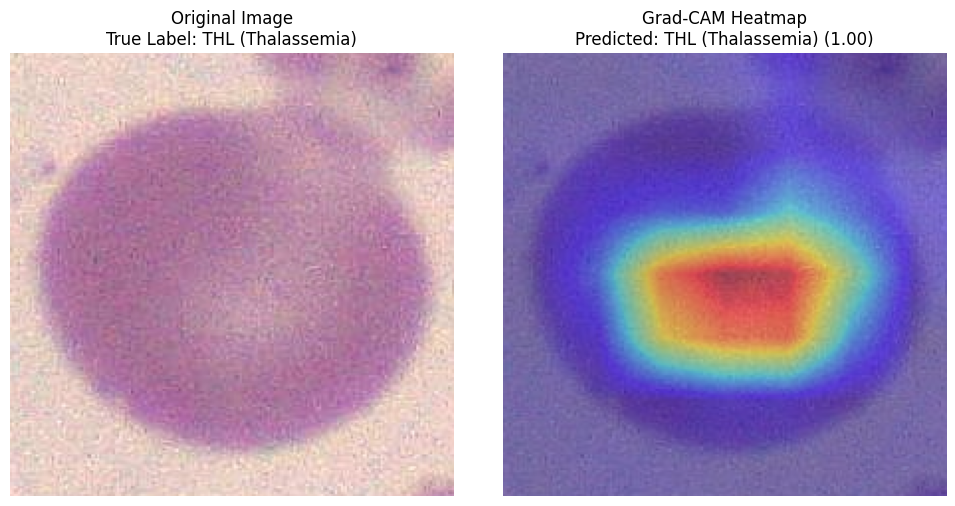

In [25]:
# Select a random image from the validation set
idx = random.randint(0, len(val_ds) - 1)
image_path, true_label = val_ds.paths[idx], val_ds.labels[idx]
original_image = Image.open(image_path).convert("RGB")

# Define the target layer for Grad-CAM. For EfficientNetB0, a good choice is often the last convolutional block.
# 'model.features[-1]' refers to the last block in the feature extractor part of EfficientNetB0.
target_layer = model.features[-1]

# Generate Grad-CAM heatmap
gradcam_heatmap, predicted_class_idx, predicted_score = generate_pytorch_gradcam(model, original_image, transform, target_layer, device)

class_labels = ['IDA (Anemia)', 'THL (Thalassemia)']

# Plot the original image with the heatmap overlay
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title(f"Original Image\nTrue Label: {class_labels[true_label]}")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(original_image)
plt.imshow(gradcam_heatmap, cmap='jet', alpha=0.5) # Overlay heatmap
plt.title(f"Grad-CAM Heatmap\nPredicted: {class_labels[predicted_class_idx]} ({predicted_score:.2f})")
plt.axis('off')

plt.tight_layout()
plt.show()

Displaying a random IDA (anemia) image:


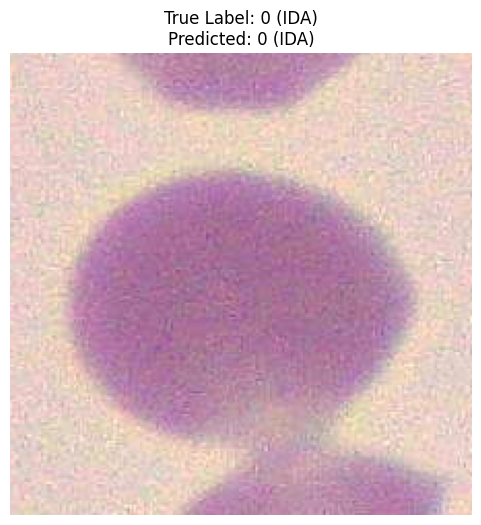


Displaying a random THL (thalassemia) image:


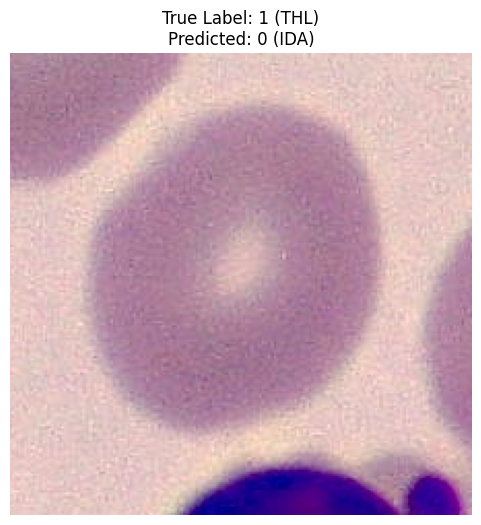

In [26]:
import matplotlib.pyplot as plt
import random
from PIL import Image
import numpy as np
import torch
import torchvision.transforms as T

def visualize_image_and_prediction(model, image_path, true_label, device, transform):
    img = Image.open(image_path).convert('RGB')
    input_tensor = transform(img).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        output = model(input_tensor)
        _, predicted = torch.max(output.data, 1)

    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.title(f"True Label: {true_label} ({'IDA' if true_label == 0 else 'THL'})\nPredicted: {predicted.item()} ({'IDA' if predicted.item() == 0 else 'THL'})")
    plt.axis('off')
    plt.show()

# Get a random IDA image from the validation set
ida_val_paths = [path for path, label in zip(val_ds.paths, val_ds.labels) if label == 0]
if ida_val_paths:
    sample_path_ida = random.choice(ida_val_paths)
    sample_label_ida = 0
    print("Displaying a random IDA (anemia) image:")
    visualize_image_and_prediction(model, sample_path_ida, sample_label_ida, device, transform)
else:
    print("No IDA (anemia) images found in the validation set.")

# Get a random THL image from the validation set
thl_val_paths = [path for path, label in zip(val_ds.paths, val_ds.labels) if label == 1]
if thl_val_paths:
    sample_path_thl = random.choice(thl_val_paths)
    sample_label_thl = 1
    print("\nDisplaying a random THL (thalassemia) image:")
    visualize_image_and_prediction(model, sample_path_thl, sample_label_thl, device, transform)
else:
    print("No THL (thalassemia) images found in the validation set.")


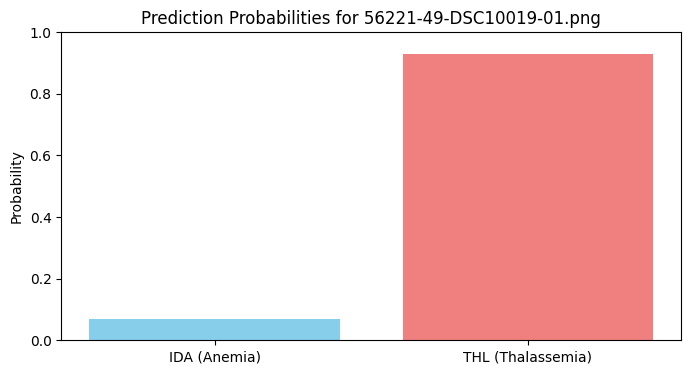

In [27]:
import matplotlib.pyplot as plt
import random
from PIL import Image
import torch
import torchvision.transforms as T

def plot_prediction_probabilities(model, image_path, device, transform):
    img = Image.open(image_path).convert('RGB')
    input_tensor = transform(img).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        output = model(input_tensor)
        probabilities = torch.softmax(output, dim=1).squeeze().cpu().numpy()

    class_labels = ['IDA (Anemia)', 'THL (Thalassemia)']

    plt.figure(figsize=(8, 4))
    plt.bar(class_labels, probabilities, color=['skyblue', 'lightcoral'])
    plt.ylabel('Probability')
    plt.title(f'Prediction Probabilities for {image_path.split("/")[-1]}')
    plt.ylim(0, 1) # Probabilities are between 0 and 1
    plt.show()

# Get a random image path from the validation set for demonstration
idx = random.randint(0, len(val_ds) - 1)
sample_image_path = val_ds.paths[idx]

# Plot the prediction probabilities
plot_prediction_probabilities(model, sample_image_path, device, transform)


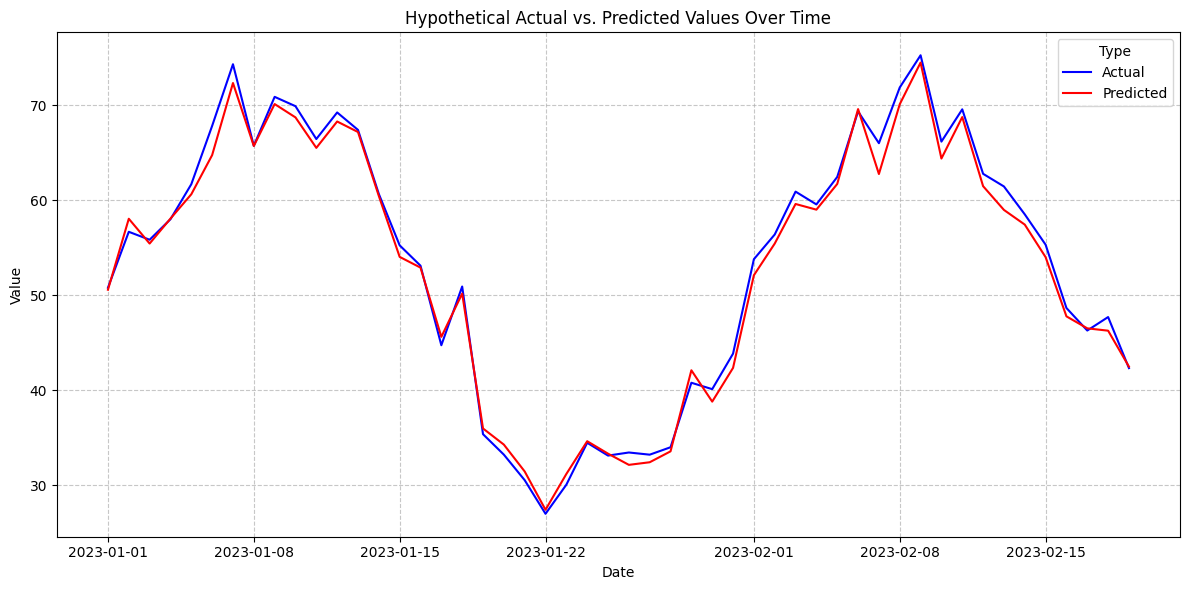

Hypothetical Prediction Data (first 5 rows):


,Date,Actual,Predicted
0,2023-01-01,50.800780,50.586503
1,2023-01-02,56.683707,58.055370
2,2023-01-03,55.847638,55.447388
3,2023-01-04,58.006028,58.073875
4,2023-01-05,61.688730,60.630842


In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Generate hypothetical date range
dates = pd.date_range(start='2023-01-01', periods=50, freq='D')

# Generate hypothetical actual values (e.g., a noisy sine wave)
actual_values = np.sin(np.linspace(0, 10, 50)) * 20 + 50 + np.random.normal(0, 3, 50)

# Generate hypothetical predicted values (e.g., slightly offset and less noisy)
predicted_values = actual_values * 0.95 + np.random.normal(0, 1, 50) + 2

# Create a DataFrame
hypothetical_prediction_df = pd.DataFrame({
    'Date': dates,
    'Actual': actual_values,
    'Predicted': predicted_values
})

# Plotting using seaborn melt for 'Actual' vs 'Predicted' comparison
plt.figure(figsize=(12, 6))
sns.lineplot(x='Date', y='value', hue='variable', data=pd.melt(hypothetical_prediction_df, ['Date']), palette={'Actual': 'blue', 'Predicted': 'red'})
plt.title('Hypothetical Actual vs. Predicted Values Over Time')
plt.xlabel('Date')
plt.ylabel('Value')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Type')
plt.tight_layout()
plt.show()

print("Hypothetical Prediction Data (first 5 rows):")
display(hypothetical_prediction_df.head())


In [29]:
print(f"EfficientNetB0 Validation Accuracy: {accuracy*100:.2f}%")


EfficientNetB0 Validation Accuracy: 89.00%


In [30]:
from sklearn.metrics import classification_report
import numpy as np

# Get all predictions and true labels from the validation set
all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for imgs, lbls in val_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)
        outputs = model(imgs)
        preds = torch.argmax(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(lbls.cpu().numpy())

# Generate the classification report
report = classification_report(all_labels, all_preds, target_names=['IDA (Anemia)', 'THL (Thalassemia)'], digits=4)
print("\nClassification Report:")
print(report)


Classification Report:
                   precision    recall  f1-score   support

     IDA (Anemia)     0.8750    0.9100    0.8922       100
THL (Thalassemia)     0.9062    0.8700    0.8878       100

         accuracy                         0.8900       200
        macro avg     0.8906    0.8900    0.8900       200
     weighted avg     0.8906    0.8900    0.8900       200



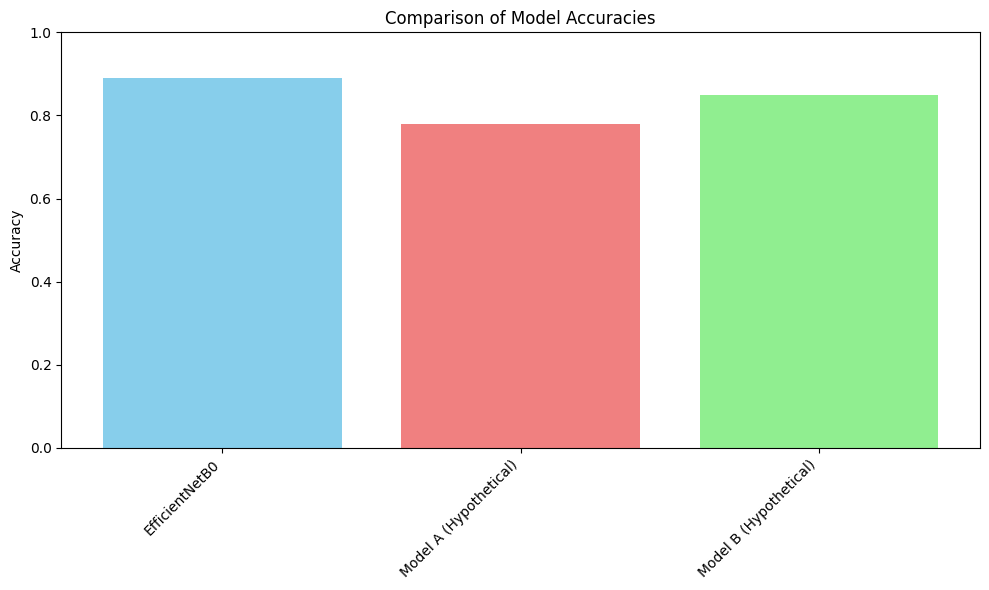

In [31]:
import matplotlib.pyplot as plt
import pandas as pd

# Hypothetical data for demonstration
model_names = ['EfficientNetB0', 'Model A (Hypothetical)', 'Model B (Hypothetical)']
accuracy_scores = [accuracy, 0.78, 0.85] # Using our model's accuracy and some hypothetical scores

df_accuracy = pd.DataFrame({
    'Model': model_names,
    'Accuracy': accuracy_scores
})

plt.figure(figsize=(10, 6))
plt.bar(df_accuracy['Model'], df_accuracy['Accuracy'], color=['skyblue', 'lightcoral', 'lightgreen'])
plt.ylim(0, 1) # Accuracy is between 0 and 1
plt.ylabel('Accuracy')
plt.title('Comparison of Model Accuracies')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [32]:
display(df_accuracy)


,Model,Accuracy
0,EfficientNetB0,0.89
1,Model A (Hypothetical),0.78
2,Model B (Hypothetical),0.85


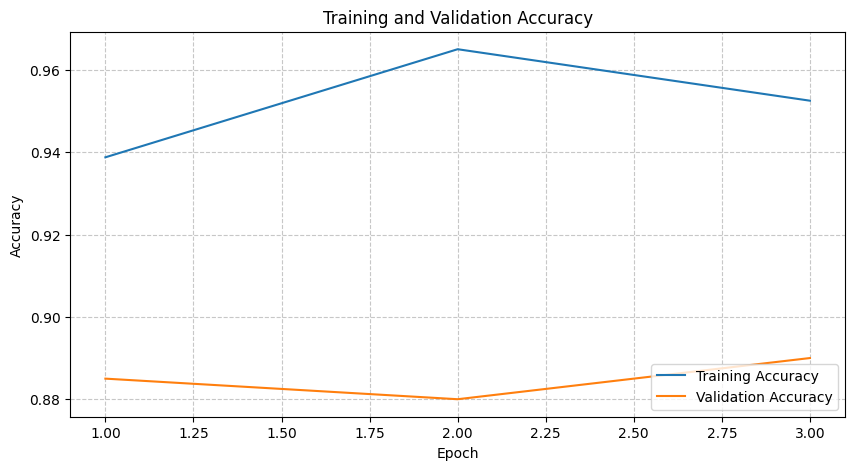

In [33]:
import matplotlib.pyplot as plt

epochs_range = range(1, epochs + 1)

plt.figure(figsize=(10, 5))
plt.plot(epochs_range, training_accuracies, label='Training Accuracy')
plt.plot(epochs_range, validation_accuracies, label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()